In [1]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.lines import Line2D

from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from subprocess import run, PIPE
import sys
import os
from sklearn.neighbors import KernelDensity
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [2]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [3]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [4]:
latitude = [30,60]


In [5]:
ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IFS_2.8km_on_cesm2_grid_summer_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IFS_2.8km_off_cesm2_grid_summer_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IFS_cycle3_cesm2_grid_summer_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IFS_cycle4_historical_cesm2_grid_summer_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/ICON_cycle3_cesm2_grid_summer_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/ICON_cycle4_cesm2_grid_summer_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IMERG_cesm2_grid_summer_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
#ifs_cycle4 = ifs_cycle4.isel(year=slice(0,30))
#ifs_cycle4 = ifs_cycle4.stack(sample=("year", "time"))
icon_cycle4 = icon_cycle4.isel(year=slice(0,5))
#icon_cycle4 = icon_cycle4.stack(sample=("year", "time"))



In [6]:
print(ifs_on)

<xarray.DataArray '__xarray_dataarray_variable__' (year: 1, lat: 32, lon: 288)> Size: 37kB
[9216 values with dtype=int32]
Coordinates:
  * lat      (lat) float64 256B 30.63 31.57 32.51 33.46 ... 57.96 58.9 59.84
  * lon      (lon) float64 2kB 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
Dimensions without coordinates: year


In [7]:
print(icon_cycle4)

<xarray.DataArray '__xarray_dataarray_variable__' (year: 5, lat: 32, lon: 288)> Size: 184kB
[46080 values with dtype=int32]
Coordinates:
  * lat      (lat) float64 256B 30.63 31.57 32.51 33.46 ... 57.96 58.9 59.84
  * lon      (lon) float64 2kB 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
Dimensions without coordinates: year


In [8]:

land_sea_cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
land_sea_cesm2 = land_sea_cesm2[0,:,:]
indexer = ((land_sea_cesm2.lat>=latitude[0]) & (land_sea_cesm2.lat<=latitude[1]))
land_sea_cesm2 = land_sea_cesm2.where(indexer,drop=True)
land_sea_cesm2 = land_sea_cesm2.assign_coords(lat=imerg.lat, lon=imerg.lon)   # CESM2 grid (all datasets are regridded to it)

ifs_on_land = ifs_on.where(land_sea_cesm2 > 0, np.nan)
ifs_off_land = ifs_off.where(land_sea_cesm2 > 0, np.nan)
ifs_cycle3_land = ifs_cycle3.where(land_sea_cesm2 > 0, np.nan)
ifs_cycle4_land = ifs_cycle4.where(land_sea_cesm2 > 0, np.nan)
icon_cycle3_land = icon_cycle3.where(land_sea_cesm2 > 0, np.nan)
icon_cycle4_land = icon_cycle4.where(land_sea_cesm2 > 0, np.nan)
imerg_land = imerg.where(land_sea_cesm2 > 0, np.nan)



## CMIP6 multi-model distribution (replaces CESM2)

Note: unlike the other datasets in this notebook, the CMIP6 models are used on their native grids, not regridded to the CESM2 grid.

The ensemble files in `CMIP6/30-60N/ensemble` hold one file per model, with dimensions (member, year, lat, lon).
- **Per model:** only the first member is used (`CMIP6_MEMBERS_PER_MODEL = 1`; lowest r, then i, p, f, e.g. r1i1p1f1, or r2i1p1f1 if r1 does not exist), the same member as in `land_dry_spell_boxplot_CMIP6.ipynb`. All its years and land cells are pooled. Land is `sftlf > 0`, and each value gets a cos(lat) area weight.
- **Equal model weights:** each model's weights are scaled to sum to 1, so every model counts equally. The multi-model distribution is the average of the per-model distributions. For the KDE curve this equals the average of the per-model density curves.
- **Speed:** dry-spell lengths are whole days, so the weights are summed per distinct value, which gives identical quantiles. The KDE is given the bandwidth the full pooled sample would get (`cmip6_bw`), so the curve is the same as for the full sample.
- **Models without an sftlf file** (BCC-CSM2-MR): the mask of `FALLBACK_MASK_MODEL` is used, matched to the nearest grid point.

In [9]:
import re
CMIP6_ENS_DIR       = '/home/jwille/xenon_data/NextGEMS/dry_spells/CMIP6/30-60N/ensemble'
SFTLF_DIR           = '/net/atmos/data/cmip6-ng/sftlf/fx/native'
FALLBACK_MASK_MODEL = 'MPI-ESM1-2-HR'
CMIP6_YEARS         = None      # e.g. (1985, 2014) to use only those years; None = all years (1850-2014)
CMIP6_EXCLUDE       = []        # model names to leave out, e.g. ['BCC-CSM2-MR']
CMIP6_MEMBERS_PER_MODEL = 1     # first N members of each model (sorted r, i, p, f); None = all members
CMIP6_BAND_RANGE    = (10, 90)  # inter-model band in the KDE plot, percentiles across models: (0, 100) = min-max, (10, 90) = 10-90%


def member_sort_key(member):
    return [int(n) for n in re.findall(r'\d+', member)]


def member_labels(ds):
    """Member names of an ensemble file: 'member_labels' attribute (NCO version, member = 1..N)
    or the member coordinate itself (Python version, member = 'r1i1p1f1', ...)."""
    lab = ds['member'].attrs.get('member_labels') or ds.attrs.get('member_labels')
    return lab.split(',') if lab else [str(m) for m in ds['member'].values]


def weighted_quantile(values, weights, quantiles):
    sorter = np.argsort(values)
    v = values[sorter]
    w = weights[sorter]
    cumw = np.cumsum(w)
    cumw /= cumw[-1]
    return np.interp(quantiles, cumw, v)


def weighted_quantile_hist(values, weights, quantiles):
    """Weighted quantile for aggregated data (distinct values + summed weights): the first value at which
    the cumulative weight reaches q. Equals weighted_quantile() applied to the full, non-aggregated sample
    (np.interp would otherwise interpolate between neighbouring whole-day values)."""
    sorter = np.argsort(values)
    v = np.asarray(values)[sorter]
    cumw = np.cumsum(np.asarray(weights)[sorter])
    cumw /= cumw[-1]
    return v[np.minimum(np.searchsorted(cumw, np.atleast_1d(quantiles) - 1e-12), v.size - 1)].squeeze()


def nearest_regrid(src, lat, lon):
    """Nearest-neighbour match of a lat/lon field to the given lat/lon (lon periodic).
    Identical grids give exactly the original values."""
    ilat = np.abs(src.lat.values[:, None] - np.asarray(lat)[None, :]).argmin(axis=0)
    dlon = (src.lon.values[:, None] - np.asarray(lon)[None, :] + 180) % 360 - 180
    ilon = np.abs(dlon).argmin(axis=0)
    return xr.DataArray(src.values[np.ix_(ilat, ilon)], dims=('lat', 'lon'), coords={'lat': lat, 'lon': lon})


def find_sftlf(model):
    """sftlf file of a model: historical preferred, else any experiment; None if there is none."""
    pat = re.compile(rf'^sftlf_fx_{re.escape(model)}_(?P<exp>[^_]+)_(?P<mem>[^_]+)_[^_]+\.nc$')
    cands = [(m['exp'] != 'historical', [int(n) for n in re.findall(r'\d+', m['mem'])], f)
             for f in os.listdir(SFTLF_DIR) if (m := pat.match(f))]
    return os.path.join(SFTLF_DIR, sorted(cands)[0][2]) if cands else None

In [10]:
ens_pat = re.compile(r'^dry_spell_(?P<model>[^_]+)_historical_ensemble_[^_]+\.nc$')
ens_files = sorted((m['model'], f) for f in os.listdir(CMIP6_ENS_DIR) if (m := ens_pat.match(f)))
fallback_sftlf = xr.open_dataset(find_sftlf(FALLBACK_MASK_MODEL))['sftlf'].load()

cmip6_models = {}   # model -> dict(values, weights) : distinct values and their summed, normalised weights
sum_w2 = 0.0        # sum of squared per-sample weights (for the KDE bandwidth of the full pooled sample)
for model, fname in ens_files:
    if model in CMIP6_EXCLUDE:
        continue
    ds = xr.open_dataset(os.path.join(CMIP6_ENS_DIR, fname))
    labels = member_labels(ds)
    if len(labels) != ds.sizes['member']:
        raise ValueError(f'{model}: {len(labels)} member labels but {ds.sizes["member"]} members in {fname}')
    order = sorted(range(len(labels)), key=lambda i: member_sort_key(labels[i]))[:CMIP6_MEMBERS_PER_MODEL]
    members = [labels[i] for i in order]
    da = ds['dry_spell'].isel(member=order).load()                  # (member, year, lat, lon), first member(s) only
    if CMIP6_YEARS is not None:
        da = da.sel(year=slice(*CMIP6_YEARS))

    mask_path = find_sftlf(model)
    sftlf = nearest_regrid(xr.open_dataset(mask_path)['sftlf'].load() if mask_path else fallback_sftlf,
                           da.lat.values, da.lon.values)
    land = (sftlf > 0).values
    w2d = np.cos(np.deg2rad(da.lat.values))[:, None] * np.ones(da.sizes['lon'])

    vals = da.values[:, :, land]                                   # (member, year, n_land)
    wts = np.broadcast_to(w2d[land], vals.shape)
    ok = np.isfinite(vals)
    v, w = vals[ok], wts[ok]
    w = w / w.sum()                                                # every model sums to 1
    sum_w2 += np.sum(w ** 2)
    u, inv = np.unique(v, return_inverse=True)
    agg = np.bincount(inv, weights=w)
    # KDE bandwidth factor of this model's full sample (for the inter-model band in the KDE plot)
    bw_model = np.sum(w ** 2) ** (1 / 5) * np.sqrt((1 - np.sum(agg ** 2)) / (1 - np.sum(w ** 2)))
    cmip6_models[model] = dict(values=u, weights=agg, n_members=da.sizes['member'], bw=bw_model)
    print(f"{model:14s} {', '.join(members)}, {da.sizes['year']} years, {land.sum():5d} land cells"
          f"  mask: {os.path.basename(mask_path) if mask_path else FALLBACK_MASK_MODEL + ' (fallback)'}")

n_models = len(cmip6_models)
all_vals = np.unique(np.concatenate([d['values'] for d in cmip6_models.values()]))
mmm_w = np.zeros(all_vals.size)
for d in cmip6_models.values():
    mmm_w[np.searchsorted(all_vals, d['values'])] += d['weights'] / n_models

cmip6_mmm_land   = xr.DataArray(all_vals, dims='sample')           # distinct dry-spell lengths
w_cmip6_mmm_land = xr.DataArray(mmm_w,    dims='sample')           # multi-model weight of each length

# KDE bandwidth factor of the full pooled sample (Scott's rule with the effective sample size),
# corrected for the weighted-covariance estimate on the aggregated values
neff_full = 1.0 / (sum_w2 / n_models ** 2)
cmip6_bw = neff_full ** (-1 / 5) * np.sqrt((1 - np.sum(mmm_w ** 2)) / (1 - sum_w2 / n_models ** 2))
print(f'\n{n_models} models, CMIP6 multi-model KDE bandwidth factor {cmip6_bw:.4g}')

ACCESS-ESM1-5  r1i1p1f1, 165 years,  2720 land cells  mask: sftlf_fx_ACCESS-ESM1-5_historical_r1i1p1f1_native.nc
BCC-CSM2-MR    r1i1p1f1, 165 years,  4341 land cells  mask: MPI-ESM1-2-HR (fallback)
CAMS-CSM1-0    r2i1p1f1, 165 years,  4758 land cells  mask: sftlf_fx_CAMS-CSM1-0_1pctCO2_r2i1p1f1_native.nc
CESM2          r1i1p1f1, 165 years,  5119 land cells  mask: sftlf_fx_CESM2_historical_r1i1p1f1_native.nc
CNRM-ESM2-1    r1i1p1f2, 165 years,  3442 land cells  mask: sftlf_fx_CNRM-ESM2-1_historical_r2i1p1f2_native.nc
CanESM5        r1i1p2f1, 165 years,   858 land cells  mask: sftlf_fx_CanESM5_historical_r1i1p1f1_native.nc
EC-Earth3      r1i1p1f1, 165 years, 11444 land cells  mask: sftlf_fx_EC-Earth3_historical_r1i1p1f1_native.nc
FGOALS-g3      r1i1p1f1, 165 years,  1579 land cells  mask: sftlf_fx_FGOALS-g3_historical_r1i1p1f1_native.nc
GFDL-ESM4      r1i1p1f1, 165 years,  5256 land cells  mask: sftlf_fx_GFDL-ESM4_historical_r1i1p1f1_native.nc
INM-CM5-0      r1i1p1f1, 165 years,  1861 la

In [11]:
ifs_on_land = ifs_on_land.stack(sample=("year", "lat", "lon"))
ifs_off_land = ifs_off_land.stack(sample=("year", "lat", "lon"))
ifs_cycle3_land = ifs_cycle3_land.stack(sample=("year", "lat", "lon"))
ifs_cycle4_land = ifs_cycle4_land.stack(sample=("year", "lat", "lon"))
icon_cycle3_land = icon_cycle3_land.stack(sample=("year", "lat", "lon"))
icon_cycle4_land = icon_cycle4_land.stack(sample=("year", "lat", "lon"))
imerg_land = imerg_land.stack(sample=("year", "lat", "lon"))

In [12]:
ifs_on_land = ifs_on_land.where(~ifs_on_land.isnull(), drop=True)
ifs_off_land = ifs_off_land.where(~ifs_off_land.isnull(), drop=True)
ifs_cycle3_land = ifs_cycle3_land.where(~ifs_cycle3_land.isnull(), drop=True)
ifs_cycle4_land = ifs_cycle4_land.where(~ifs_cycle4_land.isnull(), drop=True)
icon_cycle3_land = icon_cycle3_land.where(~icon_cycle3_land.isnull(), drop=True)
icon_cycle4_land = icon_cycle4_land.where(~icon_cycle4_land.isnull(), drop=True)
imerg_land = imerg_land.where(~imerg_land.isnull(), drop=True)


In [13]:
# 1D cos(lat) on the CESM2 grid (IMERG is on the same grid)
lat_rad_cesm2 = np.deg2rad(imerg.lat)
coslat_cesm2 = np.cos(lat_rad_cesm2)

w_lat_cesm2 = xr.DataArray(
    coslat_cesm2,
    dims=['lat'],
    coords={'lat': imerg.lat}
)

# Broadcast to (lat, lon) on CESM2 land mask
w_cesm2_2d = w_lat_cesm2.broadcast_like(land_sea_cesm2)
w_cesm2_2d = w_cesm2_2d.where(land_sea_cesm2 > 0)


In [14]:
# CMIP6 multi-model weights (w_cmip6_mmm_land) are computed in the CMIP6 cells above


In [15]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_ifs_on_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, ifs_on.shape),
    dims=ifs_on.dims,
    coords=ifs_on.coords,
)
w_ifs_on_land = w_ifs_on_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_ifs_on_land = w_ifs_on_land.stack(sample=("year", "lat", "lon"))

# Align mask with data
w_ifs_on_land = w_ifs_on_land.where(~ifs_on_land.isnull(), drop=True)


In [16]:
print(ifs_on_land)

<xarray.DataArray '__xarray_dataarray_variable__' (sample: 4683)> Size: 37kB
array([184., 184., 184., ...,   9.,  10.,  10.])
Coordinates:
    time     object 8B 2017-01-01 00:00:00
  * sample   (sample) object 37kB MultiIndex
  * year     (sample) int64 37kB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
  * lat      (sample) float64 37kB 30.63 30.63 30.63 30.63 ... 59.84 59.84 59.84
  * lon      (sample) float64 37kB 0.0 1.25 2.5 3.75 ... 286.2 287.5 288.8 290.0


In [17]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_ifs_off_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, ifs_off.shape),
    dims=ifs_off.dims,
    coords=ifs_off.coords,
)
w_ifs_off_land = w_ifs_off_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_ifs_off_land = w_ifs_off_land.stack(sample=("year", "lat", "lon"))

# Align mask with data
w_ifs_off_land = w_ifs_off_land.where(~ifs_off_land.isnull(), drop=True)


In [18]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_ifs_cycle3_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, ifs_cycle3.shape),
    dims=ifs_cycle3.dims,
    coords=ifs_cycle3.coords,
)
w_ifs_cycle3_land = w_ifs_cycle3_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_ifs_cycle3_land = w_ifs_cycle3_land.stack(sample=("year", "lat", "lon"))

# Align mask with data
w_ifs_cycle3_land = w_ifs_cycle3_land.where(~ifs_cycle3_land.isnull(), drop=True)


In [19]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_ifs_cycle4_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, ifs_cycle4.shape),
    dims=ifs_cycle4.dims,
    coords=ifs_cycle4.coords,
)
w_ifs_cycle4_land = w_ifs_cycle4_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_ifs_cycle4_land = w_ifs_cycle4_land.stack(sample=("year", "lat", "lon"))

# Align mask with data
w_ifs_cycle4_land = w_ifs_cycle4_land.where(~ifs_cycle4_land.isnull(), drop=True)


In [20]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_icon_cycle3_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, icon_cycle3.shape),
    dims=icon_cycle3.dims,
    coords=icon_cycle3.coords,
)
w_icon_cycle3_land = w_icon_cycle3_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_icon_cycle3_land = w_icon_cycle3_land.stack(sample=("year", "lat", "lon"))

# Align mask with data
w_icon_cycle3_land = w_icon_cycle3_land.where(~icon_cycle3_land.isnull(), drop=True)


In [21]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_icon_cycle4_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, icon_cycle4.shape),
    dims=icon_cycle4.dims,
    coords=icon_cycle4.coords,
)
w_icon_cycle4_land = w_icon_cycle4_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_icon_cycle4_land = w_icon_cycle4_land.stack(sample=("year", "lat", "lon"))

# Align mask with data
w_icon_cycle4_land = w_icon_cycle4_land.where(~icon_cycle4_land.isnull(), drop=True)


In [22]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_imerg_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, imerg.shape),
    dims=imerg.dims,
    coords=imerg.coords,
)
w_imerg_land = w_imerg_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_imerg_land = w_imerg_land.stack(sample=("year", "lat", "lon"))

# Align mask with data
w_imerg_land = w_imerg_land.where(~imerg_land.isnull(), drop=True)


In [23]:
print(np.median(imerg_land))


18.0


In [24]:
print(weighted_quantile_hist(cmip6_mmm_land.values, w_cmip6_mmm_land.values, 0.5))

19.0


In [25]:
print(np.median(ifs_off_land))

18.0


In [26]:
print(np.median(ifs_on_land))

21.0


In [27]:
print(np.median(icon_cycle4_land))

15.0


In [28]:
print(np.median(icon_cycle3_land))

19.0


In [29]:
print(np.median(ifs_cycle3_land))

20.0


In [30]:
print(np.median(ifs_cycle4_land))

20.0


In [31]:
print(np.quantile(ifs_on_land,0.95))

169.0


In [32]:
print(np.quantile(ifs_off_land,0.95))

156.0


In [33]:
print(np.quantile(ifs_cycle3_land,0.95))

160.0


In [34]:
print(np.quantile(ifs_cycle4_land,0.95))

167.0


In [35]:
print(np.quantile(icon_cycle3_land,0.95))

141.0


In [36]:
print(np.quantile(icon_cycle4_land,0.95))

143.0


In [37]:
print(weighted_quantile_hist(cmip6_mmm_land.values, w_cmip6_mmm_land.values, 0.95))

133.0


In [38]:
print(np.quantile(imerg_land,0.95))

110.0


In [39]:
mask = (ifs_on_land == 184) 
percentage = (mask.sum() / ifs_on_land.size) * 100
print(f"Percentage equal to 184: {percentage.values:.2f}%")

Percentage equal to 184: 3.52%


In [40]:
mask = (ifs_off_land == 184)
percentage = (mask.sum() / ifs_off_land.size) * 100
print(f"Percentage  equal to 184: {percentage.values:.2f}%")

Percentage  equal to 184: 2.50%


In [41]:
mask = (ifs_cycle3_land == 184)
percentage = (mask.sum() / ifs_cycle3_land.size) * 100
print(f"Percentage  equal to 184: {percentage.values:.2f}%")

Percentage  equal to 184: 2.23%


In [42]:
mask = (ifs_cycle4_land == 184)
percentage = (mask.sum() / ifs_cycle4_land.size) * 100
print(f"Percentage  equal to 184: {percentage.values:.2f}%")

Percentage  equal to 184: 3.09%


In [43]:
mask = (icon_cycle3_land == 184)
percentage = (mask.sum() / icon_cycle3_land.size) * 100
print(f"Percentage  equal to 184: {percentage.values:.2f}%")

Percentage  equal to 184: 1.86%


In [44]:
mask = (icon_cycle4_land == 184)
percentage = (mask.sum() / icon_cycle4_land.size) * 100
print(f"Percentage  equal to 184: {percentage.values:.2f}%")

Percentage  equal to 184: 1.70%


In [45]:
mask = (cmip6_mmm_land == 184)
percentage = (w_cmip6_mmm_land.where(mask, 0).sum() / w_cmip6_mmm_land.sum()) * 100
print(f"Percentage  equal to 184: {percentage.values:.2f}%")

Percentage  equal to 184: 0.82%


In [46]:
mask = (imerg == 184)
percentage = (mask.sum() / imerg.size) * 100
print(f"Percentage equal to 184: {percentage.values:.2f}%")

Percentage equal to 184: 0.31%


In [47]:
mask = (ifs_on_land > 60) & (ifs_on_land < 185)
percentage = (mask.sum() / ifs_on_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 19.45%


In [48]:
mask = (ifs_off_land > 60) & (ifs_off_land < 185)
percentage = (mask.sum() / ifs_off_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 15.67%


In [49]:
mask = (ifs_cycle3_land > 60) & (ifs_cycle3_land < 185)
percentage = (mask.sum() / ifs_cycle3_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 17.27%


In [50]:
mask = (ifs_cycle4_land > 60) & (ifs_cycle4_land < 185)
percentage = (mask.sum() / ifs_cycle4_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 18.01%


In [51]:
mask = (icon_cycle3_land > 60) & (icon_cycle3_land < 185)
percentage = (mask.sum() / icon_cycle3_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 14.83%


In [52]:
mask = (icon_cycle4_land > 60) & (icon_cycle4_land < 185)
percentage = (mask.sum() / icon_cycle4_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 12.80%


In [53]:
mask = (cmip6_mmm_land > 60) & (cmip6_mmm_land < 185)
percentage = (w_cmip6_mmm_land.where(mask, 0).sum() / w_cmip6_mmm_land.sum()) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")


Percentage between 60 and 184: 15.36%


In [54]:
mask = (imerg_land > 60) & (imerg_land < 185)
percentage = (mask.sum() / imerg_land.size) * 100
print(f"Percentage between 60 and 184: {percentage.values:.2f}%")



Percentage between 60 and 184: 10.78%


In [55]:
print(imerg)

<xarray.DataArray '__xarray_dataarray_variable__' (year: 10, lat: 32, lon: 288)> Size: 369kB
array([[[111, 137, ...,  92,  56],
        [ 56,  82, ...,  55,  56],
        ...,
        [ 11,  18, ...,   8,  11],
        [ 10,  21, ...,  10,   8]],

       [[109, 115, ...,  95, 117],
        [110,  90, ...,  72,  89],
        ...,
        [ 12,  11, ...,   8,  12],
        [ 11,   8, ...,   8,   8]],

       ...,

       [[162, 162, ..., 147, 147],
        [147, 123, ..., 100, 147],
        ...,
        [ 18,  18, ...,  11,  12],
        [ 12,  14, ...,  10,  12]],

       [[117, 167, ..., 129, 115],
        [116, 118, ...,  77,  98],
        ...,
        [ 21,  30, ...,  14,  22],
        [ 14,  16, ...,  22,  22]]], dtype=int32)
Coordinates:
  * lat      (lat) float64 256B 30.63 31.57 32.51 33.46 ... 57.96 58.9 59.84
  * lon      (lon) float64 2kB 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
Dimensions without coordinates: year


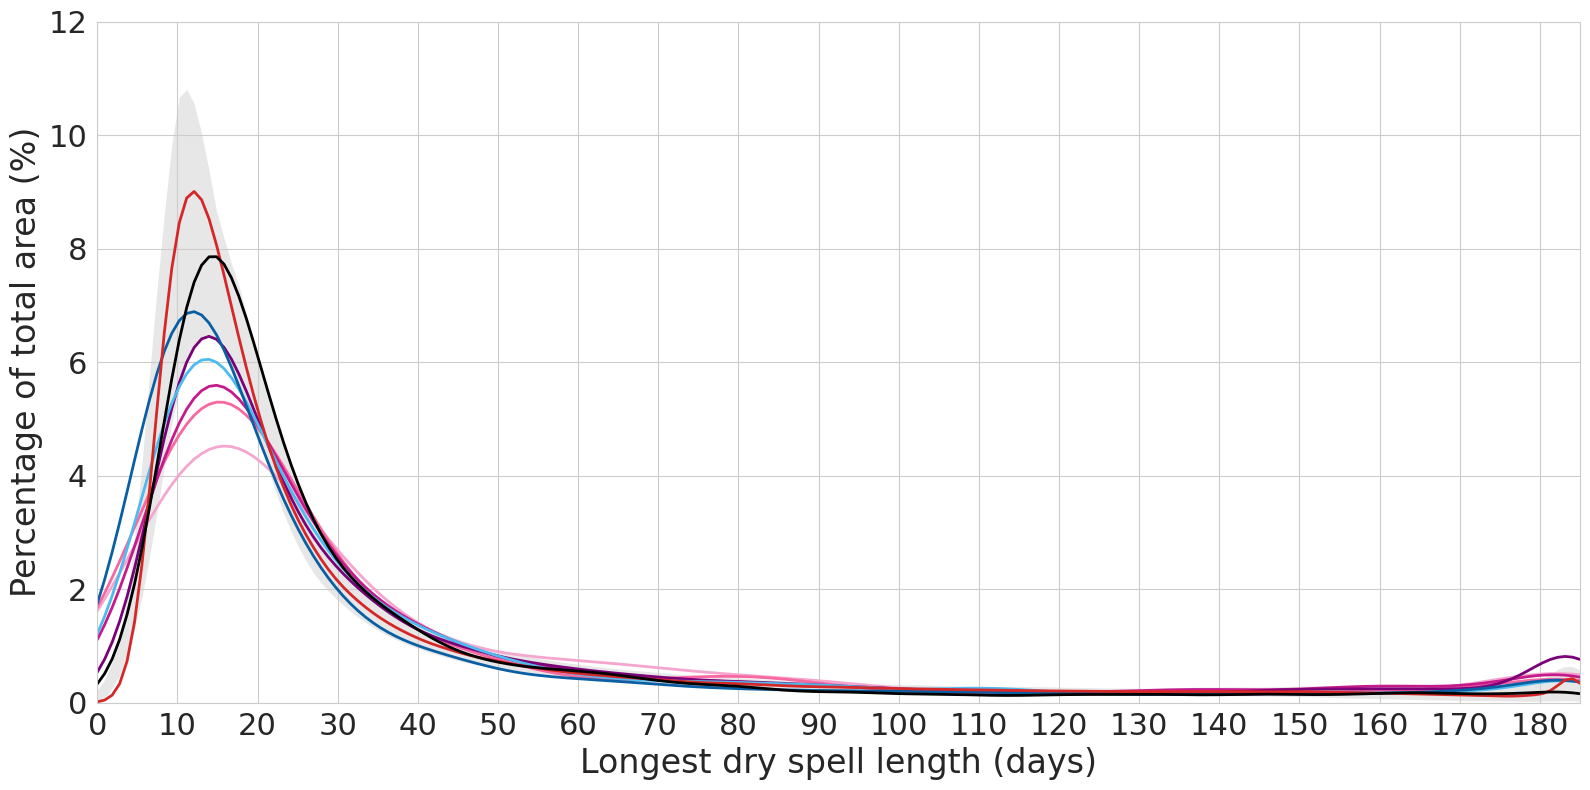

In [56]:
#with weights

# 1) Common x-range + bin width
xmin, xmax = 0, 185


bin_width  = 2.0


# For equal-area grids: weights = 1
def ones_like_da(da):
    return xr.ones_like(da)



datasets = [
    # IFS/ICON: equal-area → uniform weights
    (ifs_on_land,       w_ifs_on_land,       '#F4A6CF', 'IFS_2.8_deep_on'),
    (ifs_off_land,      w_ifs_off_land,      '#F768A1', 'IFS_2.8_deep_off'),
    (ifs_cycle3_land,   w_ifs_cycle3_land,   '#C51B8A', 'IFS_4.4-FESOM_5'),
    (ifs_cycle4_land,   w_ifs_cycle4_land,   '#7A0177', 'IFS_9-FESOM_5'),
    (icon_cycle3_land,  w_icon_cycle3_land,  '#4DBBEE', 'ICON_5'),
    (icon_cycle4_land,  w_icon_cycle4_land,  '#0A5FA3', 'ICON_9'),

    # CMIP6 multi-model & IMERG: area weights from above
    (cmip6_mmm_land,    w_cmip6_mmm_land,                '#D62728', 'CMIP6'),
    (imerg_land,        w_imerg_land,                    '#000000',       'IMERG'),
]



plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

for data_da, wts_da, color, label in datasets:
    x = data_da.values.ravel()
    w = wts_da.values.ravel()

    sns.kdeplot(
        x=x,
        weights=w,
        bw_method=cmip6_bw if label == 'CMIP6' else 'scott',   # CMIP6: bandwidth of the full pooled sample
        bw_adjust=1.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 4b) Inter-model band: range of the per-model KDE curves (each with its own full-sample bandwidth),
#     evaluated on the same x values as the CMIP6 multi-model line
from scipy.stats import gaussian_kde
cmip6_line = ax.get_lines()[[lab for *_, lab in datasets].index('CMIP6')]
x_grid = cmip6_line.get_xdata()
model_curves = np.array([gaussian_kde(d['values'], weights=d['weights'], bw_method=d['bw'])(x_grid) * 100 * bin_width
                         for d in cmip6_models.values()])
band_lo, band_hi = np.percentile(model_curves, CMIP6_BAND_RANGE, axis=0)
ax.fill_between(x_grid, band_lo, band_hi, color='#888888', alpha=0.2, linewidth=0, zorder=0)

# 5) Labels, limits, legend
xl = 'Longest dry spell length (days)'
ax.set_ylim(0, 12)
plt.xlabel(xl, fontsize=24)

plt.ylabel('Percentage of total area (%)', fontsize=24)


plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 10)
ax.set_xticks(xticks)
# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]

# then call legend with those handles
#plt.legend(
#    legend_handles,
#    legend_labels,
#    loc='upper right',
#    prop={'size': 22},
#    bbox_to_anchor=(1.0, 1.0),
#    handlelength=2.5  # longer lines in legend if you like
#)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_dry_spell_cesm2_grid_histo_CMIP6mmm_band.pdf', format='pdf',bbox_inches='tight')

plt.show()

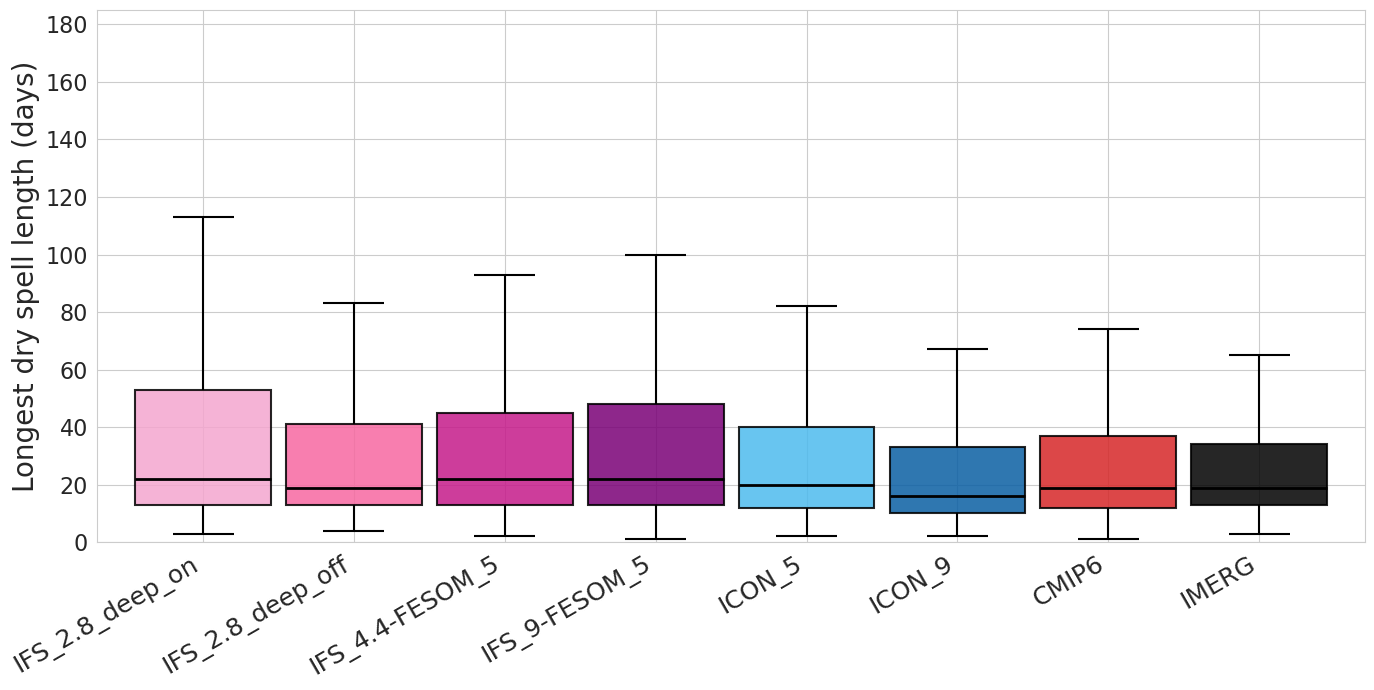

In [57]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

# ── weighted quantile helper ──────────────────────────────────────────────────
def weighted_quantile(values, weights, quantiles):
    """
    Compute weighted quantiles.
    quantiles : array-like of floats in [0, 1]
    Returns an array of the same length as quantiles.
    """
    sorter = np.argsort(values)
    v = values[sorter]
    w = weights[sorter]
    cumw = np.cumsum(w)
    cumw /= cumw[-1]           # normalise to [0, 1]
    return np.interp(quantiles, cumw, v)

# ── collect stats for every dataset ──────────────────────────────────────────
labels, colors, stats = [], [], []

for data_da, wts_da, color, label in datasets:
    x = data_da.values.ravel().astype(float)
    w = wts_da.values.ravel().astype(float)

    # drop NaNs
    mask = np.isfinite(x) & np.isfinite(w)
    x, w = x[mask], w[mask]

    wq = weighted_quantile_hist if label == 'CMIP6' else weighted_quantile   # CMIP6 is aggregated
    q25, q50, q75 = wq(x, w, [0.25, 0.50, 0.75])
    iqr = q75 - q25
    lo_fence = q25 - 1.5 * iqr
    hi_fence = q75 + 1.5 * iqr

    # whisker tips = most-extreme data point still inside the fence
    lo_whisk = x[x >= lo_fence].min() if (x >= lo_fence).any() else q25
    hi_whisk = x[x <= hi_fence].max() if (x <= hi_fence).any() else q75

    # weighted mean
    mean = np.average(x, weights=w)

    labels.append(label)
    colors.append(color)
    stats.append(dict(q25=q25, q50=q50, q75=q75,
                      lo=lo_whisk, hi=hi_whisk, mean=mean))

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 7))
sns.set_style("whitegrid")

n     = len(stats)
pos   = np.arange(1, n + 1)      # x-positions (1-based)
bw    = 0.45                      # half-width of each box

for i, (p, s, c) in enumerate(zip(pos, stats, colors)):
    # box  (IQR)
    rect = mpatches.FancyBboxPatch(
        (p - bw, s['q25']), 2 * bw, s['q75'] - s['q25'],
        boxstyle="square,pad=0", linewidth=1.5,
        edgecolor='k', facecolor=c, alpha=0.85, zorder=3
    )
    ax.add_patch(rect)

    # median line
    ax.hlines(s['q50'], p - bw, p + bw, colors='k', linewidth=2.0, zorder=4)

    # whiskers
    ax.vlines(p, s['lo'],  s['q25'], colors='k', linewidth=1.5, zorder=2)
    ax.vlines(p, s['q75'], s['hi'],  colors='k', linewidth=1.5, zorder=2)

    # whisker caps
    cap_hw = bw * 0.45
    ax.hlines(s['lo'], p - cap_hw, p + cap_hw, colors='k', linewidth=1.5, zorder=2)
    ax.hlines(s['hi'], p - cap_hw, p + cap_hw, colors='k', linewidth=1.5, zorder=2)

    # weighted mean (diamond)
    #ax.plot(p, s['mean'], marker='D', color='white',
      #      markeredgecolor='k', markersize=7, zorder=5)

# axes formatting
ax.set_xlim(0.3, n + 0.7)
ax.set_ylim(0, 185)
ax.set_xticks(pos)
ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=18)
ax.set_ylabel('Longest dry spell length (days)', fontsize=20)
ax.set_yticks(np.arange(0, 190, 20))
ax.tick_params(axis='y', labelsize=16)
#ax.set_title('Weighted Box-and-Whisker: Longest Dry Spell (mid-lat land)',
#             fontsize=18, pad=12)

# legend explaining markers
legend_elements = [
    Line2D([0], [0], color='k', linewidth=2,    label='Median'),
    Line2D([0], [0], marker='D', color='w',
           markerfacecolor='white', markeredgecolor='k',
           markersize=8,                         label='Weighted mean'),
    mpatches.Patch(facecolor='grey', edgecolor='k', alpha=0.85,
                                                 label='IQR (25–75 %)'),
    Line2D([0], [0], color='k', linewidth=1.5,  label='Whiskers (1.5 × IQR)'),
]
#ax.legend(handles=legend_elements, loc='upper right', fontsize=13,
#          framealpha=0.9)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_dry_spell_cesm2_grid_boxplot_CMIP6mmm.pdf',
            format='pdf', bbox_inches='tight')
plt.show()